In [29]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msn

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder, KBinsDiscretizer, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, recall_score, precision_score, mean_squared_error, RocCurveDisplay, mean_absolute_percentage_error

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

import category_encoders as ce

import warnings
warnings.filterwarnings('ignore')

## DATA UNDERSTANDING

In [3]:
# practice with tips dataset
tips = sns.load_dataset('tips')
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [4]:
# check data nullity, unique value
pd.set_option('display.max_colwidth', None)

pd.DataFrame({
    'feature': tips.columns.values,
    'data_type': tips.dtypes.values,
    'null': tips.isna().mean().values * 100,
    'negative': [True if tips[i].dtype == int and (tips[i] < 0).any() else False for i in tips.columns],
    'n_unique': tips.nunique().values,
    'sample_unique': [tips[i].unique() for i in tips.columns]
})

,feature,data_type,null,negative,n_unique,sample_unique
0,total_bill,float64,0.0,False,229,"[16.99, 10.34, 21.01, 23.68, 24.59, 25.29, 8.77, 26.88, 15.04, 14.78, 10.27, 35.26, 15.42, 18.43, 14.83, 21.58, 10.33, 16.29, 16.97, 20.65, 17.92, 20.29, 15.77, 39.42, 19.82, 17.81, 13.37, 12.69, 21.7, 19.65, 9.55, 18.35, 15.06, 20.69, 17.78, 24.06, 16.31, 16.93, 18.69, 31.27, 16.04, 17.46, 13.94, 9.68, 30.4, 18.29, 22.23, 32.4, 28.55, 18.04, 12.54, 10.29, 34.81, 9.94, 25.56, 19.49, 38.01, 26.41, 11.24, 48.27, 13.81, 11.02, 17.59, 20.08, 16.45, 3.07, 20.23, 15.01, 12.02, 17.07, 26.86, 25.28, 14.73, 10.51, 27.2, 22.76, 17.29, 19.44, 16.66, 10.07, 32.68, 15.98, 34.83, 13.03, 18.28, 24.71, 21.16, 28.97, 22.49, 5.75, 16.32, 22.75, 40.17, 27.28, 12.03, 12.46, 11.35, 15.38, 44.3, 22.42, ...]"
1,tip,float64,0.0,False,123,"[1.01, 1.66, 3.5, 3.31, 3.61, 4.71, 2.0, 3.12, 1.96, 3.23, 1.71, 5.0, 1.57, 3.0, 3.02, 3.92, 1.67, 3.71, 3.35, 4.08, 2.75, 2.23, 7.58, 3.18, 2.34, 4.3, 1.45, 2.5, 2.45, 3.27, 3.6, 3.07, 2.31, 2.24, 2.54, 3.06, 1.32, 5.6, 6.0, 2.05, 2.6, 5.2, 1.56, 4.34, 3.51, 1.5, 1.76, 6.73, 3.21, 1.98, 3.76, 2.64, 3.15, 2.47, 1.0, 2.01, 2.09, 1.97, 3.14, 2.2, 1.25, 3.08, 4.0, 2.71, 3.4, 1.83, 2.03, 5.17, 5.85, 3.25, 4.73, 3.48, 1.64, 4.06, 4.29, 2.55, 5.07, 1.8, 2.92, 1.68, 2.52, 4.2, 1.48, 2.18, 2.83, 6.7, 2.3, 1.36, 1.63, 1.73, 2.74, 5.14, 3.75, 2.61, 4.5, 1.61, 10.0, 3.16, 5.15, 3.11, ...]"
2,sex,category,0.0,False,2,"['Female', 'Male'] Categories (2, object): ['Male', 'Female']"
3,smoker,category,0.0,False,2,"['No', 'Yes'] Categories (2, object): ['Yes', 'No']"
4,day,category,0.0,False,4,"['Sun', 'Sat', 'Thur', 'Fri'] Categories (4, object): ['Thur', 'Fri', 'Sat', 'Sun']"
5,time,category,0.0,False,2,"['Dinner', 'Lunch'] Categories (2, object): ['Lunch', 'Dinner']"
6,size,int64,0.0,False,6,"[2, 3, 4, 1, 6, 5]"


In [5]:
# check duplicates
print(f'duplicated data: {tips.duplicated().sum()}')
print(f'duplicated data percentage: {tips.duplicated().sum()/len(tips)*100:.2f}%')

duplicated data: 1
duplicated data percentage: 0.41%


In [6]:
# duplicate handling
tips.drop_duplicates(keep='last', inplace=True, ignore_index=True)

<Axes: >

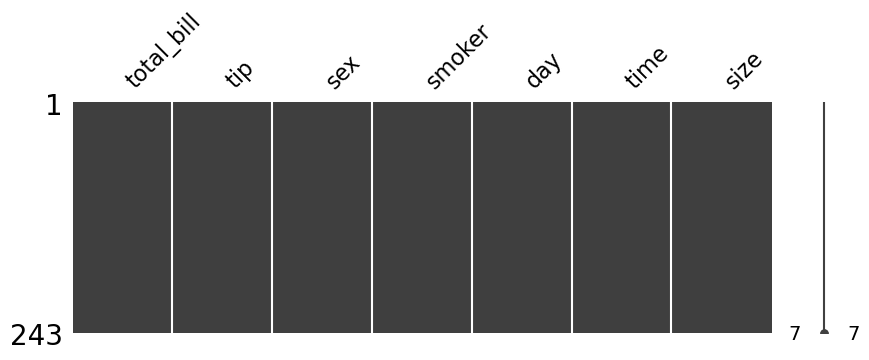

In [7]:
# missing values
msn.matrix(tips, figsize=(10,3))

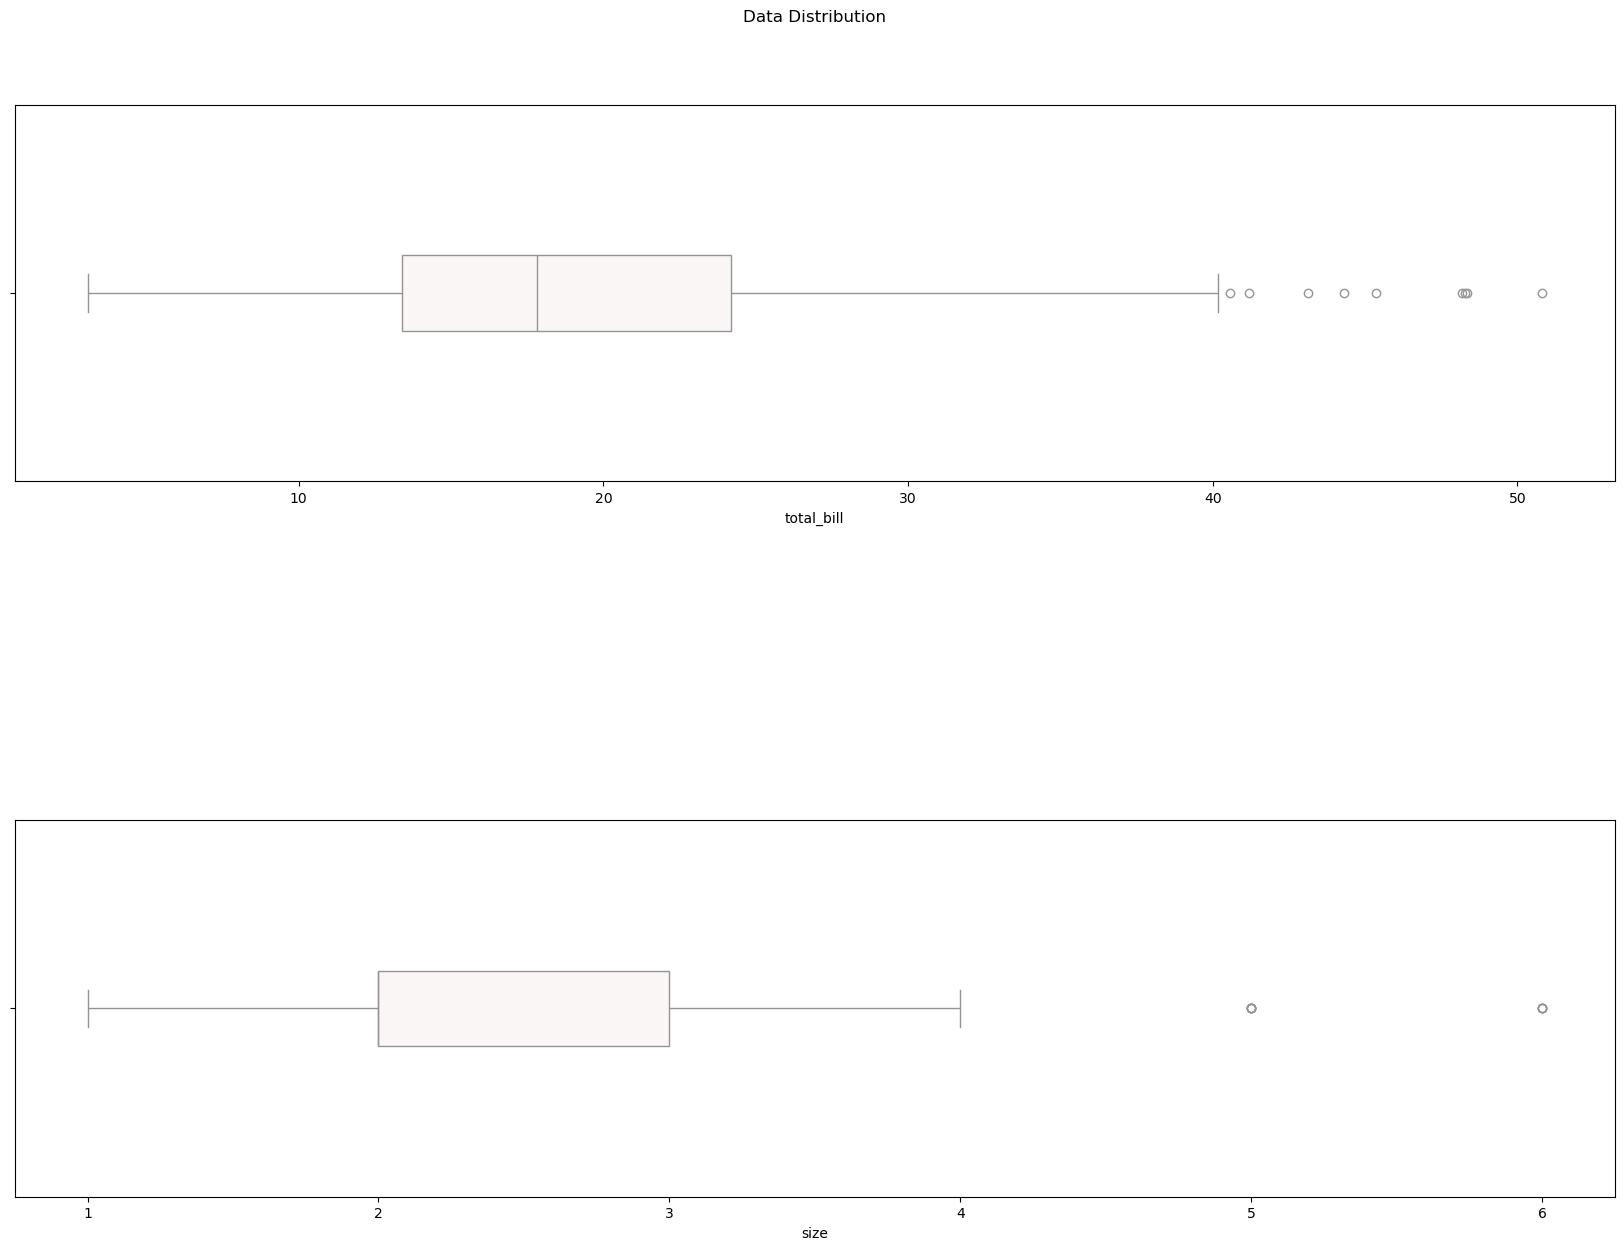

In [8]:
# outliers
fig, ax = plt.subplots(2,1, figsize=(20,14))

sns.boxplot(x='total_bill', data=tips,width=0.2,palette='vlag',ax=ax[0])
sns.boxplot(x='size',data=tips,width=0.2,palette='vlag',ax=ax[1])

ax[0].set_title('Data Distribution', y=1.2)
plt.subplots_adjust(left=0.1,bottom=0.1,right=0.9,wspace=0.1,hspace=0.9)
plt.show()

In [11]:
# handling outliers
numerical = ['total_bill', 'size']
def calc_outliers(data, column):
    Q1 = data[column].quantile(.25)
    Q3 = data[column].quantile(.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound
outlier_data = []
for i in numerical:
    outliers_result, lower_bound, upper_bound = calc_outliers(tips, i)
    total_outlier = len(outliers_result)
    outlier_percentage = round(total_outlier/len(tips[i])*100,2)
    outlier_data.append([i, total_outlier, outlier_percentage, lower_bound, upper_bound])
outlier_df = pd.DataFrame(outlier_data, columns=['column', 'total_outlier', 'percentage', 'lower_bound', 'upper_bound'])
outlier_df

,column,total_outlier,percentage,lower_bound,upper_bound
0,total_bill,9,3.7,-2.8125,40.3675
1,size,9,3.7,0.5000,4.5000


In [13]:
# multicollinearity
numerical_data = tips[numerical]

vif = pd.DataFrame()
vif['vif_factor'] = [variance_inflation_factor(numerical_data.values,i) for i in range(numerical_data.shape[1])]
vif['feature'] = numerical_data.columns

vif.round(2)

,vif_factor,feature
0,8.67,total_bill
1,8.67,size


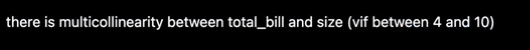

In [14]:
# Fetaure selection
X = tips.drop('tip',axis=1)
y = tips['tip']

# split
X_train,x_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0
)

X_train.shape,x_test.shape

((194, 6), (49, 6))

# Model Experiment

In [30]:
# setup base parameter for preprocessing pipeline
transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(drop='first'),['sex', 'smoker', ' day', 'time']),

],remainder='passthrough')

scaler = RobustScaler()

In [34]:
# define all model which we will try to explore
lasso = Lasso()
linreg = LinearRegression()
knn = KNeighborsRegressor()
dtree = DecisionTreeRegressor()


In [56]:
# Model benchmarking
models = [lasso, linreg, knn, dtree]

# Define evaluation metrics
mape_mean = []
mape_std = []
mape_all = []
model_name = []

# Find the best model
for i in models:
    model_pipeline = Pipeline([
        ('preprocessing', transformer),
        ('scaling', scaler),
        ('modeling', i)
    ])
    
    model_cv = cross_val_score(
        model_pipeline,
        X_train,
        y_train,
        cv=5,
        scoring='neg_mean_absolute_percentage_error'
    )

    mape_mean.append(model_cv.mean())
    mape_std.append(model_cv.std())
    mape_all.append(model_cv.round(4))
    model_name.append(i.__class__.__name__)

In [57]:
# show the output
pd.DataFrame({
    'model' : model_name,
    'mean':mape_mean,
    'std':mape_std,
    'all mape value': mape_all
}).sort_values(by='mean',ascending=False)

,model,mean,std,all mape value
1,LinearRegression,-0.280511,0.040152,"[-0.2658, -0.2555, -0.3605, -0.262, -0.2588]"
2,KNeighborsRegressor,-0.301080,0.054454,"[-0.3165, -0.2876, -0.3925, -0.2253, -0.2835]"
3,DecisionTreeRegressor,-0.348373,0.085321,"[-0.3123, -0.255, -0.5037, -0.3663, -0.3045]"
0,Lasso,-0.413548,0.064625,"[-0.4362, -0.3056, -0.4671, -0.3777, -0.4811]"


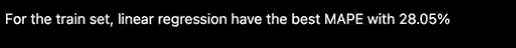

In [51]:
# test score
models = [lasso,linreg,knn,dtree]

# evaluation
mape_score = []
model_name = []

for i in models:
    model_pipeline = Pipeline([
        ('preprocessing', transformer),
        ('scaling', scaler),
        ('modeling', i)
    ])
    # fitting
    model_pipeline.fit(X_train,y_train)

    # model predict
    y_pred_test = model_pipeline.predict(x_test)

    # evaluate
    mape = mean_absolute_percentage_error(y_pred_test,y_test)
    mape_score.append(mape)
    model_name.append(i.__class__.__name__)


In [52]:
# predict output
pd.DataFrame({
    'model': model_name,
    'mape score' : mape_score
}).sort_values(by='mape score',ascending=True)

,model,mape score
1,LinearRegression,0.272802
2,KNeighborsRegressor,0.305717
0,Lasso,0.327690
3,DecisionTreeRegressor,0.408709


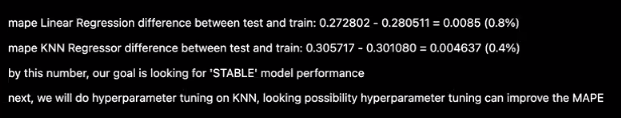

# hyperparameter tuning for KNN

In [60]:
# define the hyperparameter space
param_grid = {
    'modeling__n_neighbors' : range(3,30,2)
}

In [61]:
# enable GridSearchCV
knn = KNeighborsRegressor()

# model pipeline
knn_pipeline = Pipeline(
   [ ('preprocessing', transformer),
    ('scaling',scaler),
    ('modeling',knn)]
)

# tuning
tuned_model = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_absolute_percentage_error',
    n_jobs=-1
)

#fitting
tuned_model.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('onehot',
                                                                         OneHotEncoder(drop='first'),
                                                                         ['sex',
                                                                          'smoker',
                                                                          'day',
                                                                          'time'])])),
                                       ('scaling', RobustScaler()),
                                       ('modeling', KNeighborsRegressor())]),
             n_jobs=-1, param_grid={'modeling__n_neighbors': range(3, 30, 2)},
             scoring='neg_mean_absolute_percentage_error')

In [67]:
# best score
print(f'BEST MAPE in train set: {tuned_model.best_score_:.3f}')

# best n_neighbors
print(f'BEST PARAMs in train set: {tuned_model.best_params_}')

BEST MAPE in train set: -0.293
BEST PARAMs in train set: {'modeling__n_neighbors': 15}


In [65]:
pd.DataFrame(tuned_model.cv_results_)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modeling__n_neighbors,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.041227,0.005103,0.022226,0.013130,3,{'modeling__n_neighbors': 3},-0.329338,-0.254070,-0.408175,-0.271050,-0.306477,-0.313822,0.054031,10
1,0.034570,0.012258,0.016864,0.004434,5,{'modeling__n_neighbors': 5},-0.316454,-0.287592,-0.392521,-0.225336,-0.283496,-0.301080,0.054454,4
2,0.037599,0.009973,0.016002,0.009571,7,{'modeling__n_neighbors': 7},-0.314181,-0.290246,-0.365181,-0.232044,-0.310060,-0.302342,0.042980,5
3,0.026799,0.007836,0.017800,0.012284,9,{'modeling__n_neighbors': 9},-0.332044,-0.282464,-0.359556,-0.263390,-0.307494,-0.308990,0.034274,8
4,0.040613,0.023816,0.013013,0.001532,11,{'modeling__n_neighbors': 11},-0.329730,-0.271381,-0.352994,-0.271927,-0.304762,-0.306159,0.032039,7
5,0.026120,0.003726,0.012998,0.002000,13,{'modeling__n_neighbors': 13},-0.314621,-0.262417,-0.342884,-0.265753,-0.306153,-0.298366,0.030537,3
6,0.038597,0.014946,0.012000,0.001673,15,{'modeling__n_neighbors': 15},-0.312064,-0.250371,-0.350980,-0.258393,-0.294881,-0.293338,0.036723,1
7,0.030229,0.009241,0.015221,0.002867,17,{'modeling__n_neighbors': 17},-0.317116,-0.253969,-0.352037,-0.267381,-0.299707,-0.298042,0.035113,2
8,0.037698,0.014149,0.018344,0.010095,19,{'modeling__n_neighbors': 19},-0.326224,-0.251366,-0.349203,-0.276218,-0.309338,-0.302470,0.034917,6
9,0.040988,0.019448,0.015438,0.008320,21,{'modeling__n_neighbors': 21},-0.331737,-0.248395,-0.354278,-0.284474,-0.327069,-0.309191,0.037863,9


In [64]:
# best estimator
tuned_model.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('onehot',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker', 'day',
                                                   'time'])])),
                ('scaling', RobustScaler()),
                ('modeling', KNeighborsRegressor(n_neighbors=15))])

In [63]:
# let's predict with best model to the test set
best_model = tuned_model.best_estimator_

# fit
best_model = best_model.fit(X_train,y_train)

# predict
y_pred_test = best_model.predict(x_test)

# evaluate
mean_absolute_percentage_error(y_pred_test,y_test)

0.3140668803937121

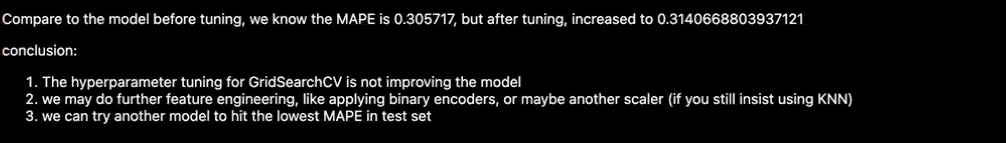